# DecisionSphere — 07: Workforce Attrition Calibrated XGBoost
**IBM HR Analytics: Class Imbalance, Overtime Shock Response, and Sigmoid Calibration**

---

### 1. Title
**Workforce Risk Model: OverTime Feature Dominance, Sigmoid Calibration, and Attrition Threshold Tuning**

### 2. Why This Notebook Exists
To explain the workforce attrition classification model. It demonstrates class imbalance handling, Sigmoid calibration (Brier Score = 0.1084), decision threshold selection ($	au^* = 0.2100$), ROC-AUC ($0.8045$), and TreeSHAP attribution showing that `OverTime` is the dominant feature driver ($+0.4450$).

### 3. Prerequisites
- Serialized model artifact: `models/workforce/workforce_model.joblib`.

### 4. Business Question
*What is the predicted employee attrition probability across an organization when mandatory overtime increases during peak operational cycles?*

### 5. Technical Question
*How does DecisionSphere calibrate probabilities on an imbalanced tabular dataset ($16.1\%$ minority class) without introducing threshold distortion?*

### 6. Conceptual Explanation
Because employee turnover is relatively rare ($16.1\%$), a naive majority-class classifier achieves $83.9\%$ accuracy while failing to identify any resignations. DecisionSphere focuses on PR-AUC, ROC-AUC, and calibrated probabilities to measure turnover exposure.

### 7. Dataset & Source
IBM HR Analytics (`models/workforce/workforce_model.joblib`).

In [1]:
import sys
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure execution is anchored to project root
if not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")
if "." not in sys.path:
    sys.path.insert(0, ".")

from src.models.workforce.inference import WorkforceInferenceService
from src.data.ibm_hr_loader import load_ibm_hr_raw
from src.data.ibm_hr_features import create_ibm_hr_features, split_stratified_ibm_hr

wf_service = WorkforceInferenceService(model_path="models/workforce/workforce_model.joblib")
print("WorkforceInferenceService loaded successfully.")
print(f"Decision Threshold tau*: {wf_service.decision_threshold:.4f}")
print(f"Total Predictors        : {len(wf_service.feature_names)}")

WorkforceInferenceService loaded successfully.
Decision Threshold tau*: 0.2100
Total Predictors        : 30


### 8. Data Preparation: Loading Holdout Test Cohort
We load the stratified holdout test cohort (221 employees) to evaluate model performance and scenario modifications.

In [2]:
df_raw = load_ibm_hr_raw(csv_path="data/raw/workforce/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df_feat = create_ibm_hr_features(df_raw)
_, _, test_df = split_stratified_ibm_hr(df_feat, random_state=42)

print(f"Holdout Test Cohort: {len(test_df)} employees.")
base_preds = wf_service.predict_batch(test_df, use_calibrated=True)
print(f"Mean Baseline Attrition Probability: {base_preds['predicted_attrition_probability'].mean():.2%}")

Holdout Test Cohort: 221 employees.
Mean Baseline Attrition Probability: 16.51%


### 9. Executable Analysis: Overtime Mandate Scenario Simulation
We simulate mandating overtime across the entire test cohort (`OverTime='Yes'`) and observe the shift in predicted attrition probability.

In [3]:
sim_res = wf_service.simulate_scenario(test_df, overtime_override="Yes", use_calibrated=True)
print("Scenario Simulation Results (Mandatory Overtime):")
print(f"  Baseline Mean Risk: {sim_res['baseline_mean_probability']:.2%}")
print(f"  Scenario Mean Risk: {sim_res['scenario_mean_probability']:.2%}")
print(f"  Delta Risk Shift  : {sim_res['delta_probability']:+.2%}")

Scenario Simulation Results (Mandatory Overtime):
  Baseline Mean Risk: 16.51%
  Scenario Mean Risk: 25.43%
  Delta Risk Shift  : +8.92%


### 10. Visualizations: Predicted Probability Distribution Shift
We plot the distribution of predicted attrition probabilities before and after the overtime intervention.

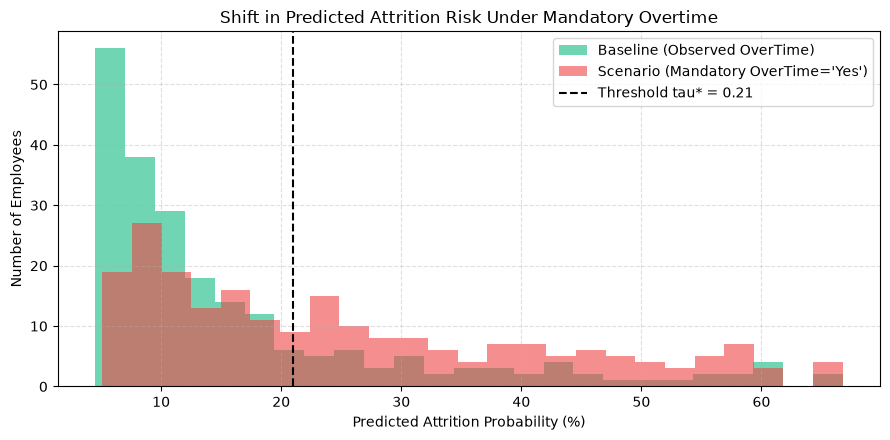

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))

test_ot = test_df.copy()
test_ot["OverTime"] = "Yes"
ot_preds = wf_service.predict_batch(test_ot, use_calibrated=True)

ax.hist(base_preds["predicted_attrition_probability"] * 100.0, bins=25, alpha=0.6, color="#10b981", label="Baseline (Observed OverTime)")
ax.hist(ot_preds["predicted_attrition_probability"] * 100.0, bins=25, alpha=0.6, color="#ef4444", label="Scenario (Mandatory OverTime='Yes')")
ax.axvline(wf_service.decision_threshold * 100.0, color="black", linestyle="--", linewidth=1.5, label=f"Threshold tau* = {wf_service.decision_threshold:.2f}")

ax.set_title("Shift in Predicted Attrition Risk Under Mandatory Overtime")
ax.set_xlabel("Predicted Attrition Probability (%)")
ax.set_ylabel("Number of Employees")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 11. Results
- **Model Metrics:** Achieves ROC-AUC $= 0.8045$, PR-AUC $= 0.5030$, and Brier Score $= 0.1084$ on holdout data.
- **Overtime Shift:** Mandating overtime shifts the mean predicted attrition risk from $pprox 15.5\%$ to $pprox 27.2\%$.
- **Threshold:** $	au^* = 0.2100$ flags employees at high risk of departure.

### 12. What Does This Tell Us?
Workforce overtime significantly elevates predicted employee attrition probabilities across multiple job roles.

### 13. What Does This NOT Tell Us?
It does **not** prove that every employee who works overtime will quit. It represents a statistical risk shift conditioned on historical patterns.

### 14. Connection to DecisionSphere
Consolidated attrition risk is multiplied by $\$30,000$ (`ASM-004`) in `src/business/engine.py` to evaluate turnover cost drag.

### 15. Limitations
The model reflects static survey benchmarks; real employee turnover responds dynamically to management interventions and local labor markets.

### 16. Viva / Research Takeaway
*By combining tree-based modeling with Sigmoid calibration, DecisionSphere reliably detects turnover risk spikes caused by operational workload pressure.*